## Import Libraries


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully.")

Libraries imported successfully.


## Load Dataset

In [33]:
df = pd.read_csv("~/Downloads/energy_consumption.csv", sep=";")
print(df.shape)
df.head()

(17544, 6)


,Start date,End date,grid load [MWh] Calculated resolutions,Grid load incl. hydro pumped storage [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Residual load [MWh] Calculated resolutions
0,"Jan 1, 2024 12:00 AM","Jan 1, 2024 1:00 AM","40,170.25","42,193.50","2,023.25","4,904.00"
1,"Jan 1, 2024 1:00 AM","Jan 1, 2024 2:00 AM","38,818.25","41,342.25","2,524.00","3,976.50"
2,"Jan 1, 2024 2:00 AM","Jan 1, 2024 3:00 AM","37,847.75","40,899.25","3,051.50","3,082.75"
3,"Jan 1, 2024 3:00 AM","Jan 1, 2024 4:00 AM","37,123.25","40,216.25","3,093.00","3,408.25"
4,"Jan 1, 2024 4:00 AM","Jan 1, 2024 5:00 AM","36,753.75","40,034.00","3,280.25","3,341.50"


## Inspect and Clean Data

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 6 columns):
 #   Column                                                             Non-Null Count  Dtype 
---  ------                                                             --------------  ----- 
 0   Start date                                                         17544 non-null  object
 1   End date                                                           17544 non-null  object
 2   grid load [MWh] Calculated resolutions                             17544 non-null  object
 3   Grid load incl. hydro pumped storage [MWh] Calculated resolutions  17544 non-null  object
 4   Hydro pumped storage [MWh] Calculated resolutions                  17544 non-null  object
 5   Residual load [MWh] Calculated resolutions                         17544 non-null  object
dtypes: object(6)
memory usage: 822.5+ KB


In [35]:
df["Start date"] = pd.to_datetime(df["Start date"])
df["End date"] = pd.to_datetime(df["End date"])

for col in df.columns[2:]:
    df[col] = pd.to_numeric(
        df[col].str.replace(",", "", regex=False)
    )

df.info()

C:\Users\USER\AppData\Local\Temp\ipykernel_21616\1206415836.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Start date"] = pd.to_datetime(df["Start date"])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 6 columns):
 #   Column                                                             Non-Null Count  Dtype         
---  ------                                                             --------------  -----         
 0   Start date                                                         17544 non-null  datetime64[ns]
 1   End date                                                           17544 non-null  datetime64[ns]
 2   grid load [MWh] Calculated resolutions                             17544 non-null  float64       
 3   Grid load incl. hydro pumped storage [MWh] Calculated resolutions  17544 non-null  float64       
 4   Hydro pumped storage [MWh] Calculated resolutions                  17544 non-null  float64       
 5   Residual load [MWh] Calculated resolutions                         17544 non-null  float64       
dtypes: datetime64[ns](2), float64(4)
memory usage: 822.5 KB


## Checking Missing Values and Duplicates

In [36]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Start date                                                           0
End date                                                             0
grid load [MWh] Calculated resolutions                               0
Grid load incl. hydro pumped storage [MWh] Calculated resolutions    0
Hydro pumped storage [MWh] Calculated resolutions                    0
Residual load [MWh] Calculated resolutions                           0
dtype: int64
Duplicates: 0


## Checking Timestamps and Daylight Saving Time

In [37]:
df["Start date"].diff().value_counts()

Start date
0 days 01:00:00    17539
0 days 02:00:00        2
0 days 00:00:00        2
Name: count, dtype: int64

### Daylight Saving Time Investigation

The timestamp checks identified irregular hourly intervals around Germany's daylight saving time transitions in March and October 2024 and 2025.

- Spring transitions: the clock moves forward, so one local hour is skipped.
- Autumn transitions: the clock moves backward, so one local hour is repeated.

These patterns are expected. All records are retained without modification.

In [38]:
dst_transitions = {
    "Spring 2024": (2159, 2165),
    "Autumn 2024": (7199, 7205),
    "Spring 2025": (10895, 10901),
    "Autumn 2025": (15935, 15941)
}

for season, (start, end) in dst_transitions.items():
    print(f"\n--- {season} ---")
    display(df.iloc[start:end, :2])


--- Spring 2024 ---


,Start date,End date
2159,2024-03-30 23:00:00,2024-03-31 00:00:00
2160,2024-03-31 00:00:00,2024-03-31 01:00:00
2161,2024-03-31 01:00:00,2024-03-31 02:00:00
2162,2024-03-31 03:00:00,2024-03-31 04:00:00
2163,2024-03-31 04:00:00,2024-03-31 05:00:00
2164,2024-03-31 05:00:00,2024-03-31 06:00:00



--- Autumn 2024 ---


,Start date,End date
7199,2024-10-27 00:00:00,2024-10-27 01:00:00
7200,2024-10-27 01:00:00,2024-10-27 02:00:00
7201,2024-10-27 02:00:00,2024-10-27 03:00:00
7202,2024-10-27 02:00:00,2024-10-27 03:00:00
7203,2024-10-27 03:00:00,2024-10-27 04:00:00
7204,2024-10-27 04:00:00,2024-10-27 05:00:00



--- Spring 2025 ---


,Start date,End date
10895,2025-03-29 23:00:00,2025-03-30 00:00:00
10896,2025-03-30 00:00:00,2025-03-30 01:00:00
10897,2025-03-30 01:00:00,2025-03-30 02:00:00
10898,2025-03-30 03:00:00,2025-03-30 04:00:00
10899,2025-03-30 04:00:00,2025-03-30 05:00:00
10900,2025-03-30 05:00:00,2025-03-30 06:00:00



--- Autumn 2025 ---


,Start date,End date
15935,2025-10-26 00:00:00,2025-10-26 01:00:00
15936,2025-10-26 01:00:00,2025-10-26 02:00:00
15937,2025-10-26 02:00:00,2025-10-26 03:00:00
15938,2025-10-26 02:00:00,2025-10-26 03:00:00
15939,2025-10-26 03:00:00,2025-10-26 04:00:00
15940,2025-10-26 04:00:00,2025-10-26 05:00:00


In [39]:
print("First record:", df["Start date"].min())
print("Last record:", df["Start date"].max())
print("Total records:", len(df))

First record: 2024-01-01 00:00:00
Last record: 2025-12-31 23:00:00
Total records: 17544


### Descriptive Statistical Analysis

Descriptive statistics were calculated to examine the distribution and range of the numerical variables. All four numerical columns contain 17,544 observations. The measurements show variation across the two-year period. Negative values were identified in the residual load variable and will be investigated further before deciding whether any data treatment is necessary.

In [40]:
df.describe()

,Start date,End date,grid load [MWh] Calculated resolutions,Grid load incl. hydro pumped storage [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Residual load [MWh] Calculated resolutions
count,17544,17544,17544.000000,17544.000000,17544.000000,17544.000000
mean,2024-12-31 12:04:28.399452672,2024-12-31 13:04:28.399452672,53084.846156,54554.834209,1469.988033,29822.042862
min,2024-01-01 00:00:00,2024-01-01 01:00:00,32413.250000,32489.750000,0.000000,-8443.140000
25%,2024-07-01 18:45:00,2024-07-01 19:45:00,45546.187500,47509.377500,73.937500,20011.490000
50%,2024-12-31 11:30:00,2024-12-31 12:30:00,53174.635000,54723.420000,556.225000,30576.375000
75%,2025-07-02 06:15:00,2025-07-02 07:15:00,59850.085000,61545.502500,2669.062500,39687.562500
max,2025-12-31 23:00:00,2026-01-01 00:00:00,75635.210000,76412.250000,6855.750000,68275.750000
std,NaN,NaN,9128.049669,8983.643575,1744.894394,14304.224530


In [41]:
numeric_cols = df.select_dtypes(include="number").columns

(df[numeric_cols] < 0).sum()


grid load [MWh] Calculated resolutions                                 0
Grid load incl. hydro pumped storage [MWh] Calculated resolutions      0
Hydro pumped storage [MWh] Calculated resolutions                      0
Residual load [MWh] Calculated resolutions                           277
dtype: int64

The residual load variable contains 277 negative observations. These values are retained because they may represent valid electricity-system conditions. No negative values were found in the other numerical variables.

### Distribution of Grid Load

A histogram was created to examine the distribution of the target variable, grid load. The histogram shows a broad distribution with two prominent peaks, indicating different concentrations of hourly electricity consumption values.

The distribution is not perfectly normal. These variations may reflect differences in electricity demand across seasons, weekdays, weekends and hours of the day. No observations were removed based on this distribution.

<Axes: ylabel='Frequency'>

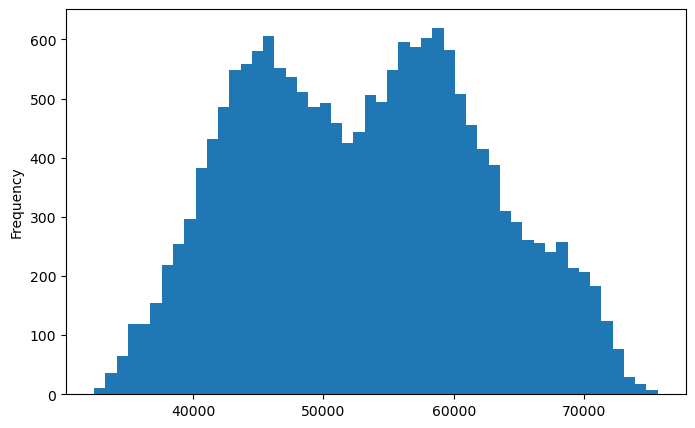

In [42]:
df["grid load [MWh] Calculated resolutions"].plot(
    kind="hist", bins=50, figsize=(8, 5)
)

## Preparing Data For Forecasting